In [2]:
!pip install pandas numpy matplotlib seaborn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

Generate a 500-row grievance dataset

In [4]:
np.random.seed(42)

n = 500

departments = [
    "Health",
    "Education",
    "Electricity",
    "Water Supply",
    "Road Transport",
    "Revenue",
    "Social Welfare"
]

states = [
    "Himachal Pradesh",
    "Uttar Pradesh",
    "Delhi",
    "Punjab",
    "Haryana"
]

complaints = {
    "Health": [
        "Hospital staff is not available",
        "Medicine shortage in government hospital"
    ],
    "Education": [
        "Scholarship payment is delayed",
        "School infrastructure needs repair"
    ],
    "Electricity": [
        "Frequent electricity cuts in village",
        "Incorrect electricity bill received"
    ],
    "Water Supply": [
        "No drinking water supply for several days",
        "Water pipeline is damaged"
    ],
    "Road Transport": [
        "Road is damaged and unsafe",
        "Public bus service is irregular"
    ],
    "Revenue": [
        "Land record correction is pending",
        "Income certificate approval is delayed"
    ],
    "Social Welfare": [
        "Pension payment has not been received",
        "Government scheme benefit is pending"
    ]
}

rows = []

for i in range(n):

    department = np.random.choice(
        departments,
        p=[0.22, 0.13, 0.20, 0.18, 0.12, 0.08, 0.07]
    )

    complaint_date = pd.Timestamp("2026-01-01") + pd.Timedelta(
        days=int(np.random.randint(0, 300))
    )

    status = np.random.choice(
        ["Resolved", "Pending", "In Progress"],
        p=[0.65, 0.20, 0.15]
    )

    resolution_date = (
        complaint_date + pd.Timedelta(
            days=int(np.random.randint(1, 31))
        )
        if status == "Resolved"
        else pd.NaT
    )

    rows.append({
        "Complaint_ID": f"GRV{i+1:04d}",
        "State": np.random.choice(states),
        "Department": department,
        "Complaint_Date": complaint_date,
        "Complaint_Description": np.random.choice(
            complaints[department]
        ),
        "Status": status,
        "Resolution_Date": resolution_date
    })

df = pd.DataFrame(rows)

# Introduce a few missing values for cleaning practice
df.loc[
    np.random.choice(df.index, 10, replace=False),
    "Complaint_Description"
] = np.nan

df.to_csv("jan_samadhan_grievances.csv", index=False)

print("Dataset Created:", df.shape)

df.head()

Dataset Created: (500, 7)


,Complaint_ID,State,Department,Complaint_Date,Complaint_Description,Status,Resolution_Date
0,GRV0001,Haryana,Electricity,2026-09-28,Frequent electricity cuts in village,Pending,NaT
1,GRV0002,Haryana,Health,2026-08-03,Medicine shortage in government hospital,Resolved,2026-08-27
2,GRV0003,Punjab,Health,2026-05-11,Medicine shortage in government hospital,Resolved,2026-05-13
3,GRV0004,Himachal Pradesh,Health,2026-07-11,Medicine shortage in government hospital,In Progress,NaT
4,GRV0005,Delhi,Water Supply,2026-09-10,No drinking water supply for several days,Resolved,2026-09-27


Task 1.1 — Load and explore the dataset

In [5]:
df = pd.read_csv(
    "jan_samadhan_grievances.csv",
    parse_dates=["Complaint_Date", "Resolution_Date"]
)

print("Dataset Shape:", df.shape)

display(df.head())

print("\nColumn Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Shape: (500, 7)


,Complaint_ID,State,Department,Complaint_Date,Complaint_Description,Status,Resolution_Date
0,GRV0001,Haryana,Electricity,2026-09-28,Frequent electricity cuts in village,Pending,NaT
1,GRV0002,Haryana,Health,2026-08-03,Medicine shortage in government hospital,Resolved,2026-08-27
2,GRV0003,Punjab,Health,2026-05-11,Medicine shortage in government hospital,Resolved,2026-05-13
3,GRV0004,Himachal Pradesh,Health,2026-07-11,Medicine shortage in government hospital,In Progress,NaT
4,GRV0005,Delhi,Water Supply,2026-09-10,No drinking water supply for several days,Resolved,2026-09-27



Column Information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Complaint_ID           500 non-null    str           
 1   State                  500 non-null    str           
 2   Department             500 non-null    str           
 3   Complaint_Date         500 non-null    datetime64[us]
 4   Complaint_Description  490 non-null    str           
 5   Status                 500 non-null    str           
 6   Resolution_Date        330 non-null    datetime64[us]
dtypes: datetime64[us](2), str(5)
memory usage: 61.0 KB

Statistical Summary:


,Complaint_ID,State,Department,Complaint_Date,Complaint_Description,Status,Resolution_Date
count,500,500,500,500,490,500,330
unique,500,5,7,NaN,14,3,NaN
top,GRV0001,Punjab,Health,NaN,Medicine shortage in government hospital,Resolved,NaN
freq,1,109,108,NaN,62,330,NaN
mean,NaN,NaN,NaN,2026-05-23 10:07:40.800000,NaN,NaN,2026-06-07 06:06:32.727272
min,NaN,NaN,NaN,2026-01-01 00:00:00,NaN,NaN,2026-01-07 00:00:00
25%,NaN,NaN,NaN,2026-03-07 00:00:00,NaN,NaN,2026-03-23 12:00:00
50%,NaN,NaN,NaN,2026-05-17 00:00:00,NaN,NaN,2026-05-26 12:00:00
75%,NaN,NaN,NaN,2026-08-07 06:00:00,NaN,NaN,2026-08-26 18:00:00
max,NaN,NaN,NaN,2026-10-27 00:00:00,NaN,NaN,2026-11-20 00:00:00


Task 1.2 — Handle missing values and clean text

In [6]:
print("Missing Values Before Cleaning:")
print(df.isnull().sum())

Missing Values Before Cleaning:
Complaint_ID               0
State                      0
Department                 0
Complaint_Date             0
Complaint_Description     10
Status                     0
Resolution_Date          170
dtype: int64


In [7]:
# Remove records with missing essential identifiers/dates
df = df.dropna(
    subset=["Complaint_ID", "Complaint_Date"]
).copy()

# Handle missing categorical values
df["Department"] = df["Department"].fillna("Unknown")
df["State"] = df["State"].fillna("Unknown")
df["Status"] = df["Status"].fillna("Unknown")

# Handle missing complaint text
df["Complaint_Description"] = (
    df["Complaint_Description"]
    .fillna("")
    .str.lower()
    .str.replace(r"[^\w\s]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Remove complaints without a usable description
df = df[df["Complaint_Description"] != ""].copy()

print("Missing Values After Cleaning:")
print(df.isnull().sum())

display(df.head())

Missing Values After Cleaning:
Complaint_ID               0
State                      0
Department                 0
Complaint_Date             0
Complaint_Description      0
Status                     0
Resolution_Date          167
dtype: int64


,Complaint_ID,State,Department,Complaint_Date,Complaint_Description,Status,Resolution_Date
0,GRV0001,Haryana,Electricity,2026-09-28,frequent electricity cuts in village,Pending,NaT
1,GRV0002,Haryana,Health,2026-08-03,medicine shortage in government hospital,Resolved,2026-08-27
2,GRV0003,Punjab,Health,2026-05-11,medicine shortage in government hospital,Resolved,2026-05-13
3,GRV0004,Himachal Pradesh,Health,2026-07-11,medicine shortage in government hospital,In Progress,NaT
4,GRV0005,Delhi,Water Supply,2026-09-10,no drinking water supply for several days,Resolved,2026-09-27


Task 1.3 — Visualization 1: Top 5 departments

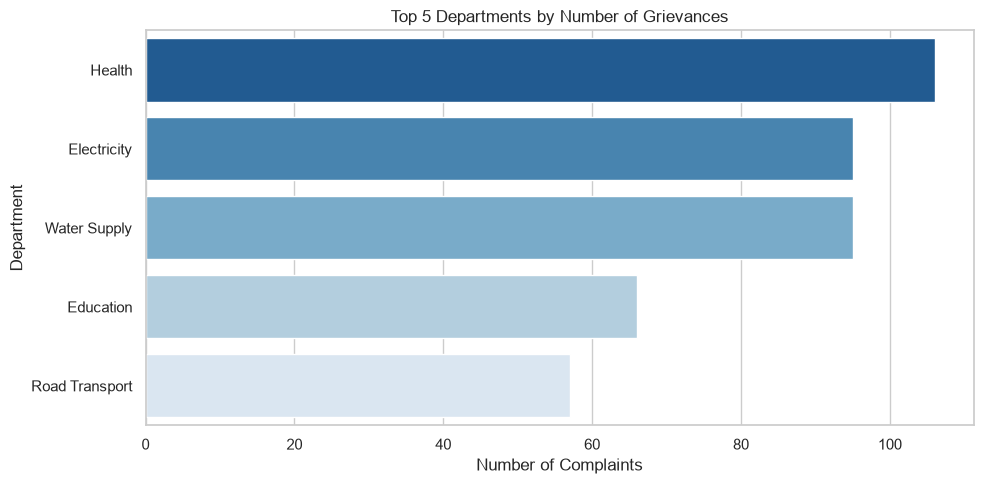

In [8]:
top5 = (
    df["Department"]
    .value_counts()
    .head(5)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top5.values,
    y=top5.index,
    hue=top5.index,
    palette="Blues_r",
    legend=False
)

plt.title("Top 5 Departments by Number of Grievances")
plt.xlabel("Number of Complaints")
plt.ylabel("Department")

plt.tight_layout()
plt.show()

Visualization 2 — Monthly complaint volume trend

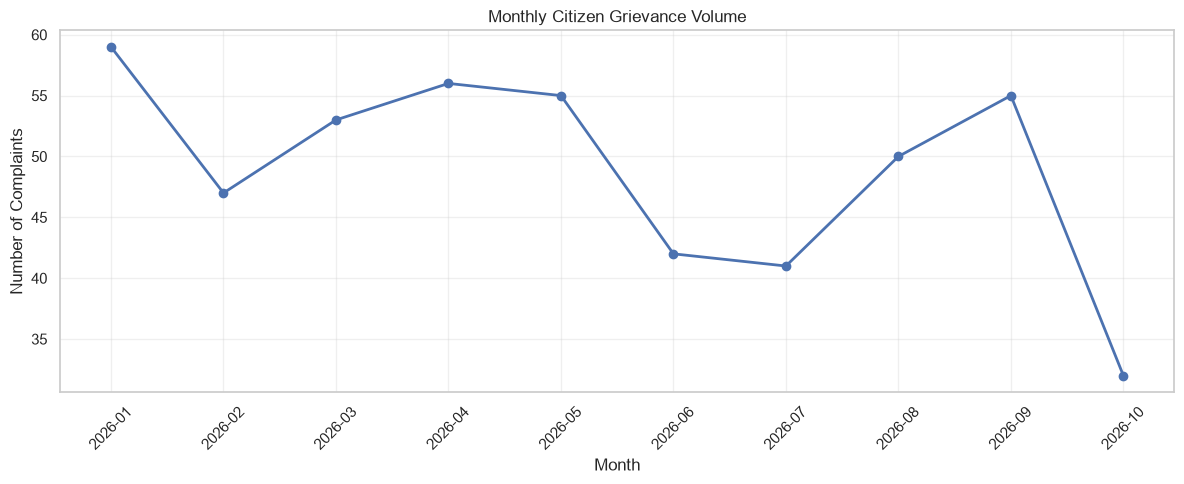

In [9]:
df["Complaint_Month"] = (
    df["Complaint_Date"]
    .dt.to_period("M")
)

monthly_complaints = (
    df.groupby("Complaint_Month")
    .size()
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_complaints.index.astype(str),
    monthly_complaints.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Citizen Grievance Volume")
plt.xlabel("Month")
plt.ylabel("Number of Complaints")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Average resolution time by department

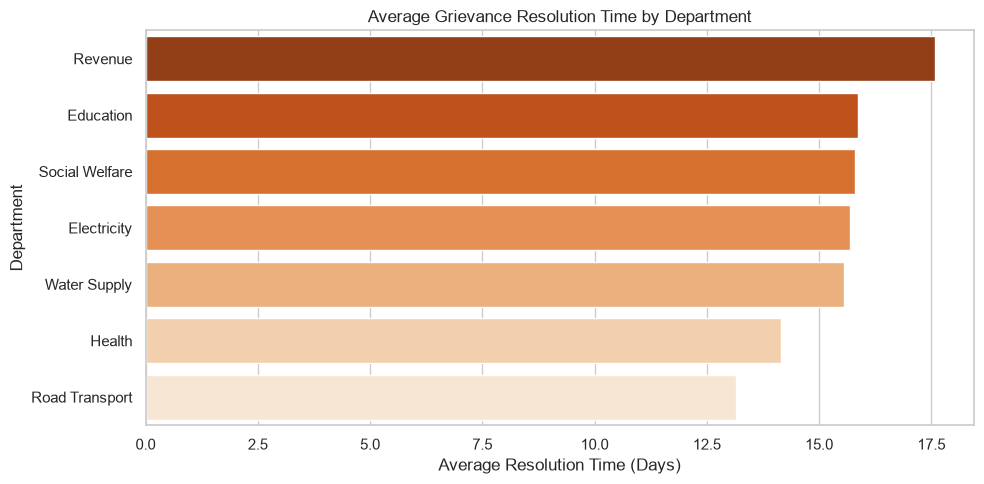

In [10]:
resolved = df[
    (df["Status"] == "Resolved") &
    (df["Resolution_Date"].notna())
].copy()

resolved["Resolution_Days"] = (
    resolved["Resolution_Date"] -
    resolved["Complaint_Date"]
).dt.total_seconds() / 86400

resolved = resolved[
    resolved["Resolution_Days"] >= 0
]

avg_resolution = (
    resolved.groupby("Department")["Resolution_Days"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=avg_resolution.values,
    y=avg_resolution.index,
    hue=avg_resolution.index,
    palette="Oranges_r",
    legend=False
)

plt.title("Average Grievance Resolution Time by Department")
plt.xlabel("Average Resolution Time (Days)")
plt.ylabel("Department")

plt.tight_layout()
plt.show()

In [11]:
df.to_csv(
    "jan_samadhan_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
